# Daily CaSR precipitation


## Shared ROI


In [1]:
OUTPUT_NAME = 'casr'
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / 'HOME_PROJECT.json').is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from tools import rotated_analysis as rotated, casr_daily as daily
from tools import rotated_plot_style as plot_style
from tools import catalog_comparison as comparison
comparison.apply_plot_style()
cfg = json.loads((ROOT / 'config.json').read_text())

# Editable controls: UTC, with an exclusive end.
START = pd.Timestamp('1980-01-01 00:00')
END = pd.Timestamp('1985-01-01 00:00')
EXAMPLE_DAY_END = pd.Timestamp('1980-01-19 12:00')

grid = rotated.prepare_grid(ROOT, cfg)
OUTPUT = rotated.output_directory(ROOT, grid, OUTPUT_NAME)
OUTPUT.mkdir(parents=True, exist_ok=True)

def show(fig, filename):
    plot_style.finish(fig, filename)
    fig.savefig(OUTPUT / filename, dpi=180, facecolor='white')
    plt.show()
    plt.close(fig)

display(rotated.grid_description(grid).to_frame())
print(f'Analysis: {START:%Y-%m-%d} to {END:%Y-%m-%d} (exclusive), UTC.')

# Daily-analysis controls.
WET_DAY_MM = 1.0
HEAVY_PERCENTILE = 95
MIN_WET_DAYS = 100
EXAMPLE_DAYS = None  # None: wettest land and ocean days, independent of either catalog.
SINGLE_TRACK_IDS = None  # None: earliest three single global detections on different days.

,Shared ROI
Native rows × columns,418 × 260
Local row / column positions (stop excluded),[0:418] / [0:260]
Included cells,108680
Rotated latitude centres (°),-29.07 to 8.46
Rotated longitude centres (°),-30.00 to -6.69
rlat cell-edge bounds (°),-29.115002 to 8.505000
rlon cell-edge bounds (°),-30.042221 to -6.642220
Land / ocean / inland water cells,70551 / 37286 / 843


Analysis: 1980-01-01 to 1985-01-01 (exclusive), UTC.


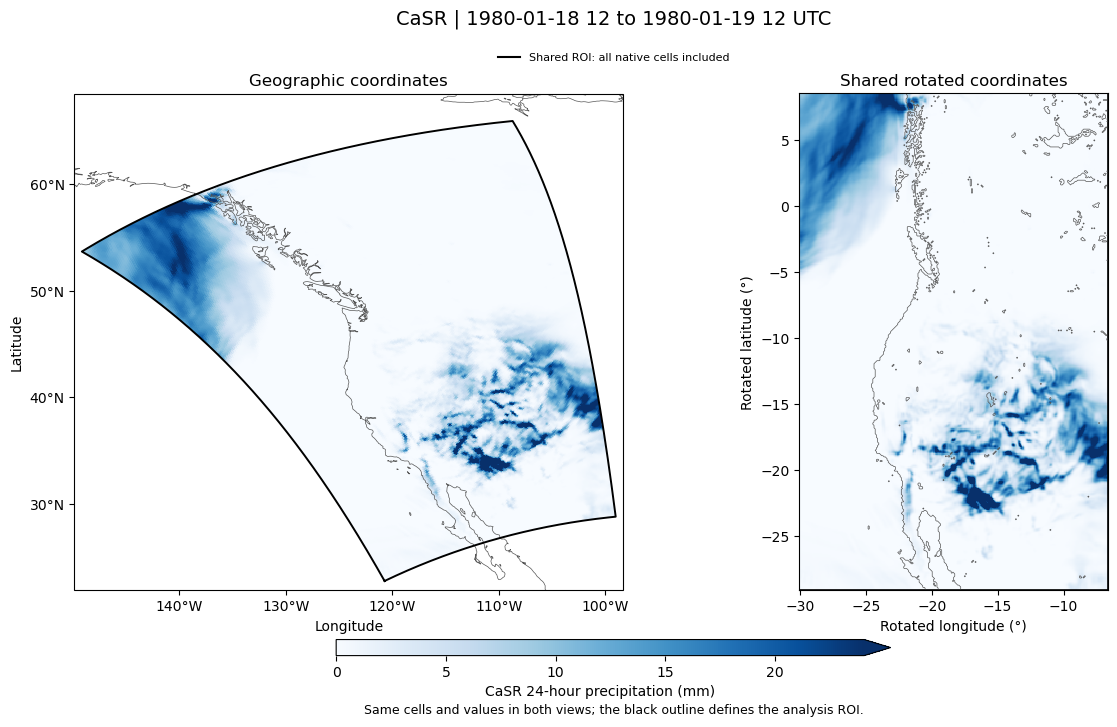

In [2]:
rain = rotated.example_rain(ROOT, cfg, grid, EXAMPLE_DAY_END)
show(rotated.plot_coordinate_views(grid, rain,
     f'CaSR | {EXAMPLE_DAY_END - pd.Timedelta(days=1):%Y-%m-%d} 12 to {EXAMPLE_DAY_END:%Y-%m-%d} 12 UTC',
     unit='CaSR 24-hour precipitation (mm)'), '01_roi_coordinates.png')

## Daily fields


In [3]:
cache = rotated.build_daily_cache(ROOT, cfg, grid, START, END)
result = daily.load_or_analyze(cache, OUTPUT, WET_DAY_MM, HEAVY_PERCENTILE, MIN_WET_DAYS)
manifest = json.loads((cache / 'manifest.json').read_text())
print(f"{result['context']['complete_daily_windows']:,} complete daily windows; "
      f"{manifest['daily_edge_hours_excluded']} boundary hours excluded.")
display(pd.Series(result['context']['domain_cells'], name='Scored cells').to_frame())

Daily metrics: cells 1–2,048 of 108,680
Daily metrics: cells 16,385–18,432 of 108,680
Daily metrics: cells 32,769–34,816 of 108,680
Daily metrics: cells 49,153–51,200 of 108,680
Daily metrics: cells 65,537–67,584 of 108,680
Daily metrics: cells 81,921–83,968 of 108,680
Daily metrics: cells 98,305–100,352 of 108,680
1,826 complete daily windows; 24 boundary hours excluded.


,Scored cells
Land,70551
Ocean,37286


## Main metrics


Daily coverage (%)  Precipitation share (%)  \
Domain Catalog                                                
Land   tARget                17.18                    41.18   
       PIKART                 3.63                    13.11   
Ocean  tARget                19.70                    53.09   
       PIKART                 9.44                    35.25   

                Heavy precipitation share (%)  Heavy-day enrichment  
Domain Catalog                                                       
Land   tARget                           61.55                  3.05  
       PIKART                           26.86                  5.17  
Ocean  tARget                           78.81                  3.50  
       PIKART                           64.41                  5.11

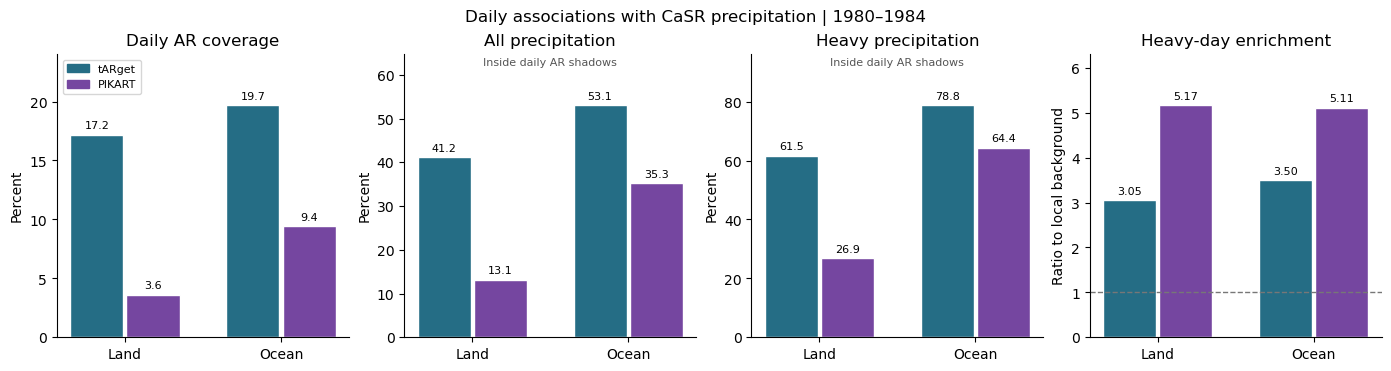

In [4]:
display(result['summary'].round(2))
show(daily.plot_summary(result), '02_daily_summary.png')

## Spatial and temporal patterns


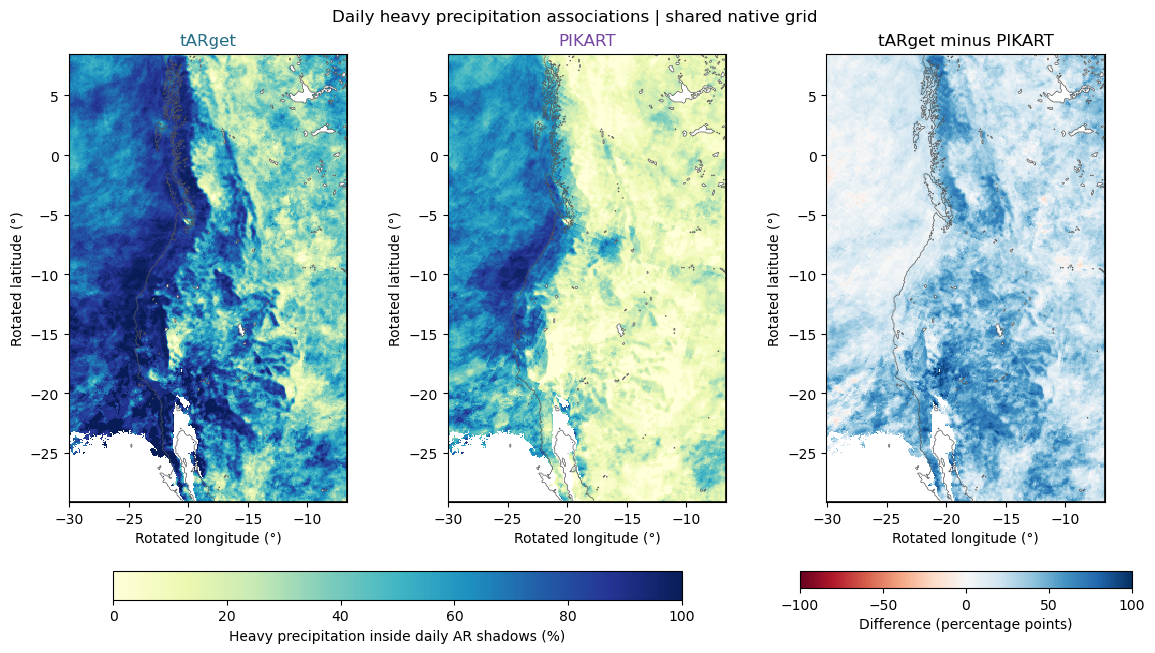

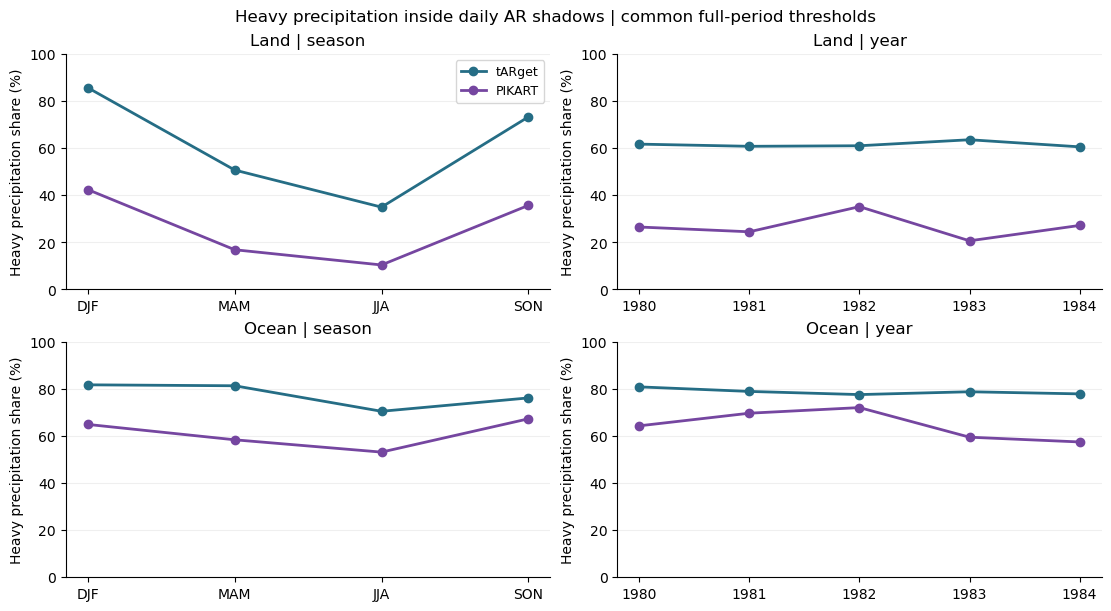

In [5]:
show(rotated.plot_daily_spatial(result), '03_spatial_heavy_associations.png')
show(daily.plot_stability(result), '04_seasonal_annual_stability.png')

## Daily shadows


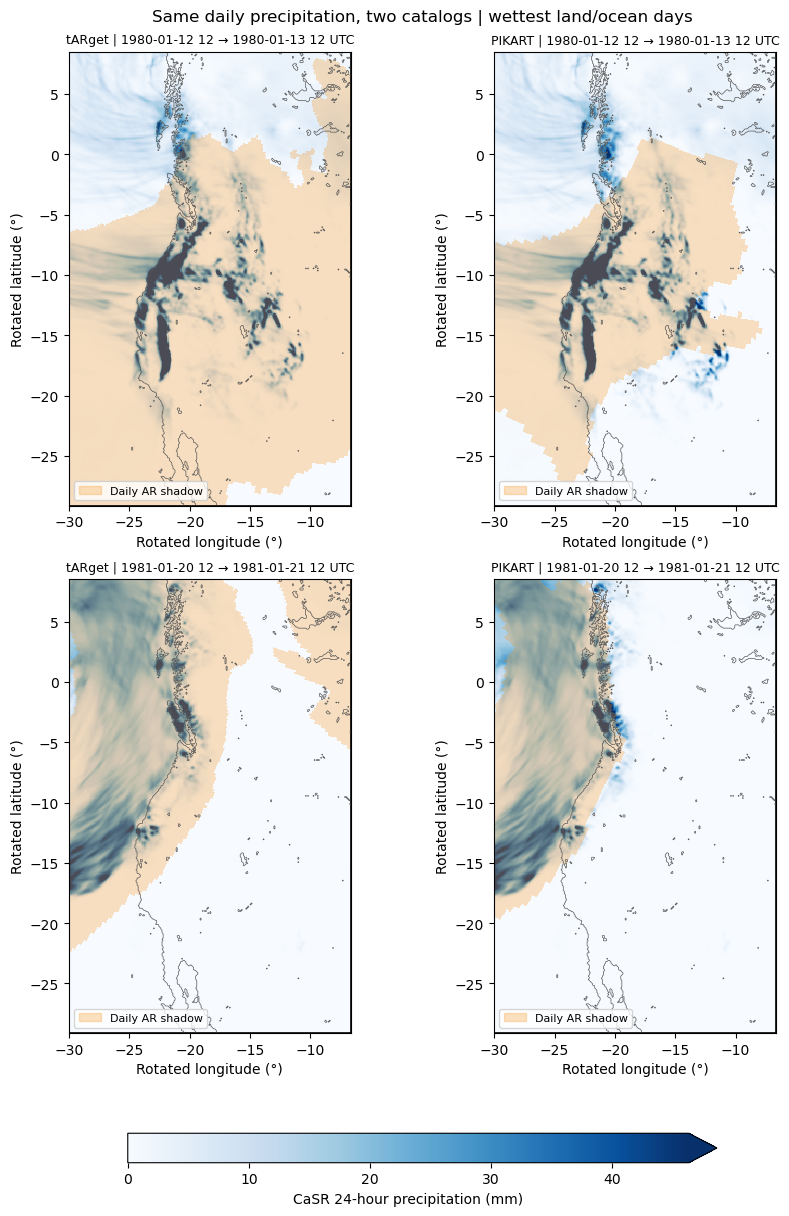

In [6]:
show(rotated.plot_daily_examples(result, EXAMPLE_DAYS), '05_daily_shadow_comparison.png')

## Single-detection tracks


tARget native ROI: 1/7,308 snapshots
tARget native ROI: 513/7,308 snapshots
tARget native ROI: 1,025/7,308 snapshots
tARget native ROI: 1,537/7,308 snapshots
tARget native ROI: 2,049/7,308 snapshots
tARget native ROI: 2,561/7,308 snapshots
tARget native ROI: 3,073/7,308 snapshots
tARget native ROI: 3,585/7,308 snapshots
tARget native ROI: 4,097/7,308 snapshots
tARget native ROI: 4,609/7,308 snapshots
tARget native ROI: 5,121/7,308 snapshots
tARget native ROI: 5,633/7,308 snapshots
tARget native ROI: 6,145/7,308 snapshots
tARget native ROI: 6,657/7,308 snapshots
tARget native ROI: 7,169/7,308 snapshots


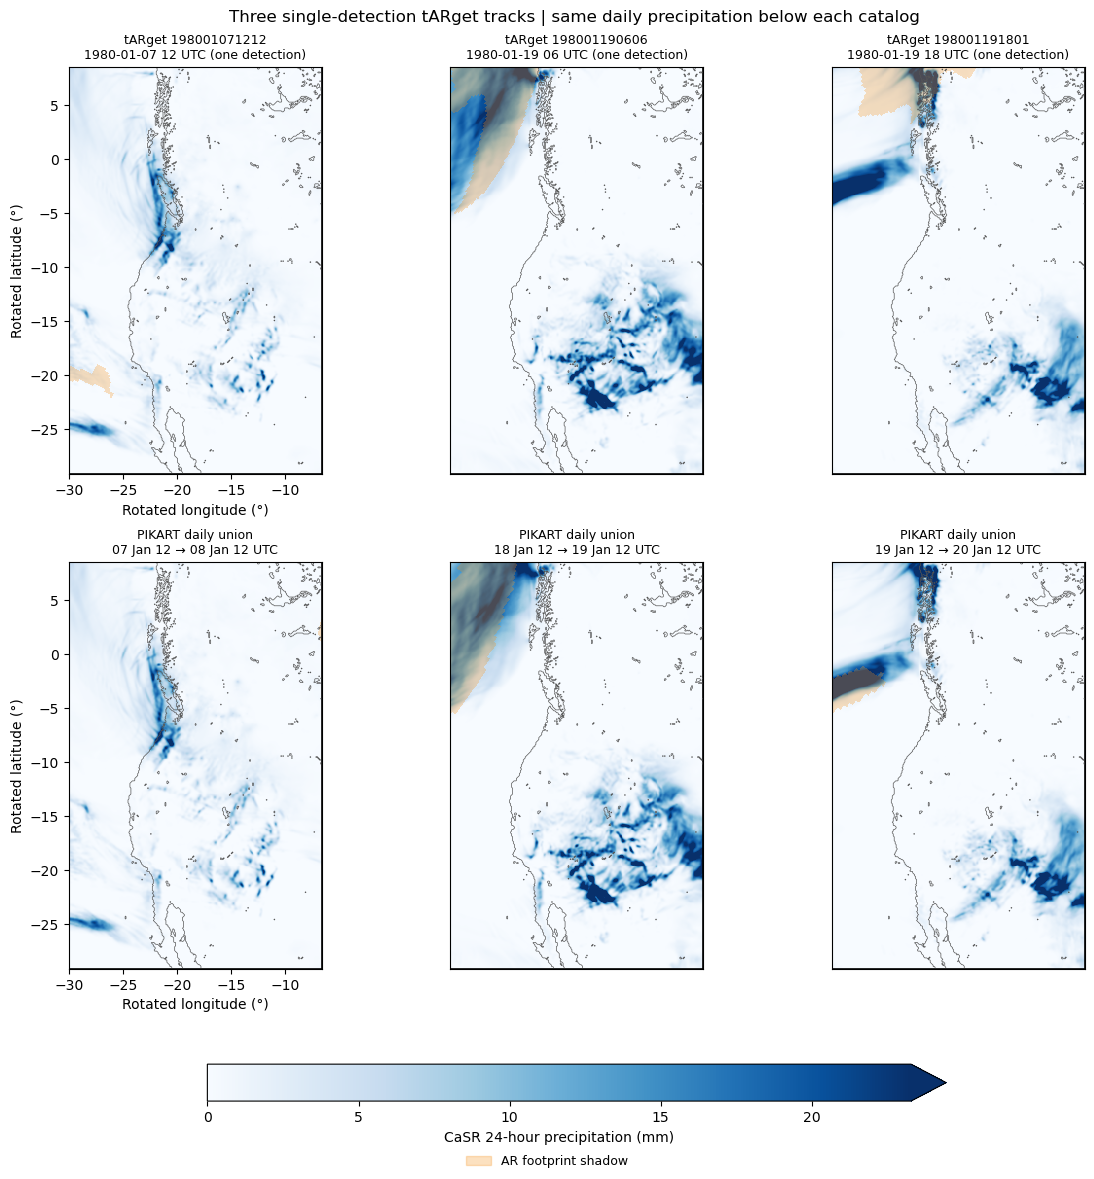

,tARget ID,Detection UTC,Day end UTC,Mean daily precipitation in tARget footprint (mm),Daily PIKART overlap of tARget footprint (%),PIKART IDs overlapping,PIKART IDs elsewhere in shared ROI
0,198001071212,1980-01-07 12:00:00,1980-01-08 12:00:00,1.315697,0.000000,None,64918
1,198001190606,1980-01-19 06:00:00,1980-01-19 12:00:00,13.210569,59.966686,64943,None
2,198001191801,1980-01-19 18:00:00,1980-01-20 12:00:00,8.863321,0.000000,None,"64943, 64965"


In [7]:
target_events = rotated.catalog_analysis(ROOT, cfg, grid, 'tARget', START, END)
fig, cases = rotated.plot_single_event_comparison(ROOT, cfg, result, target_events, SINGLE_TRACK_IDS)
cases = cases.rename(columns={name: name.replace('daily rain', 'daily precipitation') for name in cases.columns})
show(fig, '06_single_detection_catalog_comparison.png')
display(cases)
cases.to_csv(OUTPUT / 'single_detection_daily_examples.csv', index=False)